<a href="https://colab.research.google.com/github/Viditp25/flyrank-intern-/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Viditp25/flyrank-intern-/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Setup and data contract

This notebook uses the anonymized starter CSV and the same target definition as ML-09: `target = 1` when `trend_direction == "down"`. It builds an auditable, human-reviewed queue, not an automated publishing system.

The notebook looks for `data/raw/content_refresh_anonymized.csv` relative to the repository. If the file is not present, it tries the repository's public raw-data URL. If neither works, place the approved CSV at that path and rerun.

**Safety:** IDs are used only for grouping/splitting and are not model features or exported. No client names, URLs, titles, or private queries are printed or exported.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

RANDOM_STATE = 42
DATA_REL = Path("data/raw/content_refresh_anonymized.csv")
DATA_URL = "https://raw.githubusercontent.com/Viditp25/flyrank-intern-/main/data/raw/content_refresh_anonymized.csv"

def find_repo_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / DATA_REL).is_file():
            return candidate
    return None

repo_root = find_repo_root()
if repo_root is not None:
    data_path = repo_root / DATA_REL
    df = pd.read_csv(data_path)
    print(f"Loaded approved local dataset: {data_path}")
else:
    try:
        df = pd.read_csv(DATA_URL)
        repo_root = Path.cwd().resolve()
        print("Loaded dataset from the configured repository raw URL.")
    except Exception as exc:
        raise FileNotFoundError(
            f"Could not load the dataset locally or from the configured URL. "
            f"Place the approved CSV at {DATA_REL} and rerun. Original error: {exc}"
        )

required = ["client_id", "content_id", "trend_direction", "impressions_90d", "impressions_last_30d", "impressions_prev_30d"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Required columns missing: {missing}")
labels = df["trend_direction"].astype("string").str.strip().str.lower()
valid_labels = {"down", "stable", "up", "new", "flat"}
if (labels.isna() | ~labels.isin(valid_labels)).any():
    raise ValueError("Missing or unexpected trend_direction labels.")
df["target"] = labels.eq("down").astype(int)
model_df = df.loc[df.client_id.notna() & df.content_id.notna()].copy().reset_index(drop=True)
print(f"Rows: {len(df):,} | columns: {len(df.columns):,} | modeling rows: {len(model_df):,}")
print(f"Declining-label base rate: {model_df.target.mean():.2%}")

Loaded dataset from the configured repository raw URL.
Rows: 30,000 | columns: 45 | modeling rows: 30,000
Declining-label base rate: 54.21%


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### Ranking method and reason-code policy

The queue ranks pages by the Logistic Regression score for the dataset's **observed declining label**. The score is a review-priority signal, not a verified forecast. Each row receives a transparent reason code based on available signals and a suggested first human check. A missing or contradictory signal is not treated as proof of a problem.

The grouped holdout is used to report a more conservative unseen-client evaluation. The final queue is then scored using a model fit to the available labeled starter slice; those queue scores are not out-of-sample estimates. The notebook uses a diagnostic ranking score threshold of 0.50 only to help organize review, not as an automatic action threshold.

In [2]:
# Reconstruct historical 61-90 day values and features, matching ML-09.
for metric in ["impressions", "clicks", "sessions"]:
    total = pd.to_numeric(model_df.get(f"{metric}_90d"), errors="coerce")
    last = pd.to_numeric(model_df.get(f"{metric}_last_30d"), errors="coerce")
    prev = pd.to_numeric(model_df.get(f"{metric}_prev_30d"), errors="coerce")
    if total is not None and last is not None and prev is not None:
        older = total - last - prev
        model_df[f"{metric}_days_61_90"] = older.mask(total.isna() | last.isna() | prev.isna() | older.lt(0))
    else:
        model_df[f"{metric}_days_61_90"] = np.nan
    model_df[f"{metric}_pre"] = pd.to_numeric(model_df.get(f"{metric}_prev_30d"), errors="coerce") + pd.to_numeric(model_df[f"{metric}_days_61_90"], errors="coerce")

impr_pre = pd.to_numeric(model_df["impressions_pre"], errors="coerce")
click_pre = pd.to_numeric(model_df.get("clicks_pre"), errors="coerce")
model_df["ctr_pre"] = click_pre / impr_pre.replace(0, np.nan)
older_impr = pd.to_numeric(model_df["impressions_days_61_90"], errors="coerce")
prev_impr = pd.to_numeric(model_df.get("impressions_prev_30d"), errors="coerce")
model_df["prior_momentum_pct"] = ((prev_impr - older_impr) / older_impr.replace(0, np.nan)) * 100

log_sources = [f"{m}_{window}" for m in ["impressions", "clicks", "sessions"] for window in ["days_61_90", "prev_30d", "pre"] if f"{m}_{window}" in model_df.columns]
for col in log_sources:
    vals = pd.to_numeric(model_df[col], errors="coerce")
    model_df[f"log1p_{col}"] = np.log1p(vals.where(vals >= 0))

numeric_candidates = ["search_volume", "competition", "cpc", "word_count", "char_count", "impressions_days_61_90", "clicks_days_61_90", "sessions_days_61_90", "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d", "impressions_pre", "clicks_pre", "sessions_pre", "ctr_pre", "prior_momentum_pct"] + [f"log1p_{c}" for c in log_sources]
categorical_candidates = ["competition_level", "content_type", "main_intent", "word_count_tier"]
forbidden = {"client_id", "content_id", "trend_direction", "target", "trend_pct", "impressions_last_30d", "clicks_last_30d", "sessions_last_30d", "impressions_90d", "clicks_90d", "sessions_90d"}
numeric_features = [c for c in numeric_candidates if c in model_df.columns and c not in forbidden]
categorical_features = [c for c in categorical_candidates if c in model_df.columns and c not in forbidden]
for c in numeric_features:
    model_df[c] = pd.to_numeric(model_df[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
numeric_features = [c for c in numeric_features if model_df[c].notna().any()]
feature_cols = numeric_features + categorical_features
if not feature_cols:
    raise ValueError("No permitted model features were found.")
X = model_df[feature_cols].copy()
y = model_df.target.astype(int).copy()
groups = model_df.client_id.copy()

def make_pipeline():
    transformers = []
    if numeric_features:
        transformers.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features))
    if categorical_features:
        transformers.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features))
    pre = ColumnTransformer(transformers=transformers, remainder="drop")
    return Pipeline([("preprocessor", pre), ("model", LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
holdout_model = make_pipeline()
holdout_model.fit(X.iloc[train_idx], y.iloc[train_idx])
holdout_prob = holdout_model.predict_proba(X.iloc[test_idx])[:, 1]
train_clients = set(groups.iloc[train_idx]); test_clients = set(groups.iloc[test_idx])
holdout_metrics = {
    "rows": int(len(model_df)), "features": int(len(feature_cols)),
    "train_rows": int(len(train_idx)), "test_rows": int(len(test_idx)),
    "train_clients": int(len(train_clients)), "test_clients": int(len(test_clients)),
    "client_overlap": int(len(train_clients & test_clients)),
    "test_base_rate": float(y.iloc[test_idx].mean()),
    "roc_auc": float(roc_auc_score(y.iloc[test_idx], holdout_prob)),
    "average_precision": float(average_precision_score(y.iloc[test_idx], holdout_prob)),
    "brier_score": float(brier_score_loss(y.iloc[test_idx], holdout_prob)),
}
assert holdout_metrics["client_overlap"] == 0, "Grouped holdout must have zero client overlap."
display(pd.DataFrame([holdout_metrics]).round(4))
print("Features used:", feature_cols)

,rows,features,train_rows,test_rows,train_clients,test_clients,client_overlap,test_base_rate,roc_auc,average_precision,brier_score
0,30000,29,23837,6163,25,7,0,0.511,0.6171,0.5988,0.2505


Features used: ['search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'impressions_days_61_90', 'clicks_days_61_90', 'sessions_days_61_90', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'impressions_pre', 'clicks_pre', 'sessions_pre', 'ctr_pre', 'prior_momentum_pct', 'log1p_impressions_days_61_90', 'log1p_impressions_prev_30d', 'log1p_impressions_pre', 'log1p_clicks_days_61_90', 'log1p_clicks_prev_30d', 'log1p_clicks_pre', 'log1p_sessions_days_61_90', 'log1p_sessions_prev_30d', 'log1p_sessions_pre', 'competition_level', 'content_type', 'main_intent', 'word_count_tier']


### Reason codes and action mapping

| Reason code | Evidence used | Suggested first action | Human check |
|---|---|---|---|
| `MOMENTUM_DOWN` | Prior momentum is negative and sufficiently below zero | Diagnose the historical drop; inspect query intent, SERP changes, and technical issues | Confirm trend windows and seasonality before recommending a refresh |
| `HIGH_REVIEW_SCORE` | Model score is in the top review band | Prioritize a manual performance review | Treat score as ranking signal only; compare with business importance |
| `CONTENT_GAP_REVIEW` | Content is informational / a keyword article or has an available word-count tier | Review search intent coverage, outdated facts, and missing subtopics | Do not assume longer content is better |
| `LOW_EVIDENCE` | Important historical metrics are missing or prior impressions are too small | Gather evidence before making a change | Defer action if the evidence is insufficient |
| `MIXED_SIGNALS` | Score and simple historical momentum do not agree | Review manually; do not force an action | Check label definition, seasonality, and measurement gaps |

Actions are suggestions for triage. The notebook does not assert that any specific change will improve rankings or traffic.

In [3]:
# Generate client-grouped out-of-fold scores for the ranked action queue.

from sklearn.model_selection import GroupKFold, cross_val_predict

n_clients = groups.nunique()

if n_clients < 5:
    raise ValueError(
        f"At least 5 distinct clients are required for 5-fold grouped scoring; found {n_clients}."
    )

cv = GroupKFold(n_splits=5)

queue_score = cross_val_predict(
    make_pipeline(),
    X,
    y,
    groups=groups,
    cv=cv,
    method="predict_proba",
    n_jobs=None
)[:, 1]

assert len(queue_score) == len(model_df)
assert np.isfinite(queue_score).all()
assert ((queue_score >= 0) & (queue_score <= 1)).all()

queue = pd.DataFrame(index=model_df.index)

queue["queue_row_id"] = [
    f"Q{i:06d}" for i in range(1, len(model_df) + 1)
]

queue["review_priority_score"] = queue_score

queue["priority_band"] = pd.cut(
    queue_score,
    bins=[-np.inf, 0.35, 0.50, 0.70, np.inf],
    labels=["Routine", "Review", "High review", "Highest review"],
    right=False
).astype(str)

momentum = pd.to_numeric(
    model_df["prior_momentum_pct"], errors="coerce"
)
word_count = pd.to_numeric(
    model_df["word_count"], errors="coerce"
)
prior_impr = pd.to_numeric(
    model_df["impressions_pre"], errors="coerce"
)

content_type = (
    model_df.get(
        "content_type",
        pd.Series("Unknown", index=model_df.index)
    )
    .astype("string")
    .fillna("Unknown")
    .str.lower()
)

main_intent = (
    model_df.get(
        "main_intent",
        pd.Series("Unknown", index=model_df.index)
    )
    .astype("string")
    .fillna("Unknown")
    .str.lower()
)

reason_codes = []
actions = []
review_notes = []

for pos in range(len(model_df)):
    score = float(queue_score[pos])
    mom = momentum.iloc[pos]
    impr = prior_impr.iloc[pos]
    typ = content_type.iloc[pos]
    intent = main_intent.iloc[pos]

    missing_evidence = pd.isna(impr) or impr < 100
    negative_momentum = pd.notna(mom) and mom <= -20
    positive_momentum = pd.notna(mom) and mom >= 20

    if missing_evidence:
        reason_codes.append("LOW_EVIDENCE")
        actions.append("Gather more evidence; defer content changes")
        review_notes.append(
            "Check data coverage, sample size, and recent history"
        )

    elif negative_momentum and score >= 0.50:
        reason_codes.append("MOMENTUM_DOWN+HIGH_REVIEW_SCORE")
        actions.append(
            "Investigate decline; consider a targeted content/technical review"
        )
        review_notes.append(
            "Verify trend window, intent match, seasonality, and technical health"
        )

    elif score >= 0.70:
        reason_codes.append("HIGH_REVIEW_SCORE")
        actions.append("Prioritize manual performance and intent review")
        review_notes.append(
            "Score is not a forecast; compare with business value and context"
        )

    elif (
        ("informational" in intent or "article" in typ or "blog" in typ)
        and score >= 0.50
    ):
        reason_codes.append("CONTENT_GAP_REVIEW")
        actions.append(
            "Review intent coverage, accuracy, freshness, and missing subtopics"
        )
        review_notes.append(
            "Do not add length without a demonstrated user/search need"
        )

    elif positive_momentum and score < 0.50:
        reason_codes.append("MIXED_SIGNALS")
        actions.append(
            "Monitor; avoid unnecessary refresh without further evidence"
        )
        review_notes.append(
            "Positive historical momentum conflicts with review score"
        )

    else:
        reason_codes.append("MIXED_SIGNALS")
        actions.append("Manual review only; no immediate change recommended")
        review_notes.append(
            "Check evidence quality, seasonality, and business context"
        )

queue["reason_code"] = reason_codes
queue["suggested_action"] = actions
queue["human_review_check"] = review_notes

queue["content_archetype"] = np.where(
    content_type.str.contains(
        "product|category|landing", regex=True
    ),
    "Commercial/landing page",
    np.where(
        content_type.str.contains(
            "article|blog|guide|keyword", regex=True
        ),
        "Informational/article",
        "Other/unknown archetype"
    )
)

queue["prior_momentum_pct"] = momentum.to_numpy()
queue["word_count"] = word_count.to_numpy()
queue["evidence_impressions_pre"] = prior_impr.to_numpy()

queue["model_score_is_in_sample"] = False
queue["score_method"] = "5-fold client-grouped out-of-fold"

queue = queue.sort_values(
    ["review_priority_score", "evidence_impressions_pre"],
    ascending=[False, False],
    na_position="last"
).reset_index(drop=True)

queue.insert(0, "rank", np.arange(1, len(queue) + 1))

print("Ranked action queue preview (no client/content IDs):")
display(queue.head(15).round(3))

print(
    "Queue rows:", len(queue),
    "| unique reason codes:", queue["reason_code"].nunique()
)
print("Score method: 5-fold client-grouped out-of-fold")
print("In-sample scores:", queue["model_score_is_in_sample"].sum())

assert len(queue) == len(model_df)
assert queue["queue_row_id"].is_unique
assert queue["model_score_is_in_sample"].eq(False).all()
assert queue["score_method"].eq(
    "5-fold client-grouped out-of-fold"
).all()

Ranked action queue preview (no client/content IDs):


,rank,queue_row_id,review_priority_score,priority_band,reason_code,suggested_action,human_review_check,content_archetype,prior_momentum_pct,word_count,evidence_impressions_pre,model_score_is_in_sample,score_method
0,1,Q029401,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-16.739,7676.0,303543,False,5-fold client-grouped out-of-fold
1,2,Q016533,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider a targeted conte...,"Verify trend window, intent match, seasonality...",Informational/article,-20.882,6204.0,5850,False,5-fold client-grouped out-of-fold
2,3,Q026123,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider a targeted conte...,"Verify trend window, intent match, seasonality...",Informational/article,-52.841,7449.0,7408,False,5-fold client-grouped out-of-fold
3,4,Q017335,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-0.262,5872.0,17561,False,5-fold client-grouped out-of-fold
4,5,Q023768,1.000,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,24.597,4610.0,170817,False,5-fold client-grouped out-of-fold
5,6,Q021820,1.000,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider a targeted conte...,"Verify trend window, intent match, seasonality...",Informational/article,-50.617,3097.0,379380,False,5-fold client-grouped out-of-fold
6,7,Q002033,0.999,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,-12.773,6569.0,69169,False,5-fold client-grouped out-of-fold
7,8,Q025084,0.999,Highest review,MOMENTUM_DOWN+HIGH_REVIEW_SCORE,Investigate decline; consider a targeted conte...,"Verify trend window, intent match, seasonality...",Informational/article,-30.245,5474.0,60769,False,5-fold client-grouped out-of-fold
8,9,Q017217,0.998,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,17.534,5353.0,61375,False,5-fold client-grouped out-of-fold
9,10,Q019790,0.997,Highest review,HIGH_REVIEW_SCORE,Prioritize manual performance and intent review,Score is not a forecast; compare with business...,Informational/article,7.321,6691.0,2662,False,5-fold client-grouped out-of-fold


Queue rows: 30000 | unique reason codes: 5
Score method: 5-fold client-grouped out-of-fold
In-sample scores: 0


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### Intended use and limits

**Intended user:** an SEO/content analyst or editor who can inspect search performance and page context. **Intended use:** sort a backlog so that limited review time is spent first on pages with a stronger combination of historical decline evidence and model score. The output is a starting queue for investigation, not an instruction to edit a page.

**What this evidence supports:** the model distinguishes the dataset's proxy label to a limited degree on a client-grouped holdout. In ML-09, grouped ROC-AUC was 0.6171 and average precision was 0.5988; the random split scored higher (0.7109 and 0.7222), and client composition differed. Use those figures as the previous run's results, not a promise that this notebook's newly executed run will be identical.

**Limits:** the target means `trend_direction == "down"` in the supplied snapshot; it is not a verified future decline label. Predictor timestamps/operational availability are not independently verified, and grouped validation is not time-forward validation. The queue is scored in-sample after fitting on all available rows; its scores rank review effort and are not unbiased performance estimates. Results do not establish causation, refresh lift, search-engine algorithm behavior, or business value.

In [4]:
intended_use = {
    "user": "SEO/content analyst or editor",
    "purpose": "prioritize manual review of anonymized content records",
    "unit": "one content record in the supplied anonymized starter slice",
    "output": "rank, review-priority score, reason code, suggested action, and human check",
    "not_for": ["automatic publishing or deletion", "guaranteed future decline prediction", "causal refresh-effect claims", "client-facing promises", "production prioritization without timestamp verification"],
    "validation_note": "Client-grouped holdout is not time-forward validation; queue scores are in-sample ranking scores.",
}
print(json.dumps(intended_use, indent=2))

{
  "user": "SEO/content analyst or editor",
  "purpose": "prioritize manual review of anonymized content records",
  "unit": "one content record in the supplied anonymized starter slice",
  "output": "rank, review-priority score, reason code, suggested action, and human check",
  "not_for": [
    "automatic publishing or deletion",
    "guaranteed future decline prediction",
    "causal refresh-effect claims",
    "client-facing promises",
    "production prioritization without timestamp verification"
  ],
  "validation_note": "Client-grouped holdout is not time-forward validation; queue scores are in-sample ranking scores."
}


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human-review rules and no-go list

Before any action, a person must: (1) confirm the page and current business context in an approved internal system; (2) validate the data window and recent traffic; (3) inspect query intent, SERP competition, seasonality, technical/indexing issues, conversions, and existing editorial plans; (4) decide whether the proposed work is worth the cost; and (5) record the decision and outcome for later review.

**Never automate:** publishing or deleting content; rewriting claims or regulated/sensitive advice; changing canonical/indexing/redirect settings; changing prices or offers; making a client-facing promise; treating a score as a Google ranking factor; refreshing solely to increase word count; or acting when data is missing, contradictory, or too sparse. Human approval is required for every action.

In [5]:
no_go_cases = pd.DataFrame([
    ("Automatic publish/delete", "Never; editorial and business consequences require human approval"),
    ("Technical SEO changes", "Never execute automatically; require a qualified reviewer and rollback plan"),
    ("Sensitive or regulated content", "Require subject-matter and policy review; model score is insufficient"),
    ("Missing/low-volume evidence", "Defer action and gather more evidence"),
    ("Word-count-only refresh", "Do not recommend length increases without a documented intent gap"),
    ("Client-facing guarantees", "Never claim a score predicts Google behavior or guarantees traffic lift"),
    ("Unverified timing or future-prediction claims", "No deployment claim until timestamps and time-forward evaluation are verified"),
], columns=["No-go case", "Rule"])
display(no_go_cases)

,No-go case,Rule
0,Automatic publish/delete,Never; editorial and business consequences req...
1,Technical SEO changes,Never execute automatically; require a qualifi...
2,Sensitive or regulated content,Require subject-matter and policy review; mode...
3,Missing/low-volume evidence,Defer action and gather more evidence
4,Word-count-only refresh,Do not recommend length increases without a do...
5,Client-facing guarantees,Never claim a score predicts Google behavior o...
6,Unverified timing or future-prediction claims,No deployment claim until timestamps and time-...


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### Monitoring and retraining triggers

This is a light, non-production plan. Recheck monthly while the queue is used for a pilot, and sooner after a major tracking/schema change. Monitor: label/base-rate drift; missingness in key historical metrics; score distribution; precision among reviewed top-ranked pages once outcomes mature; action acceptance/rejection and reason-code distribution; and whether review actions actually produced measurable value. Log decisions and outcomes without storing private page content in this notebook.

Retrain or recalibrate only when enough newly matured labels exist and a fresh client-grouped or time-forward evaluation is available. Trigger a review if the decline-label base rate shifts by more than 10 percentage points, key-feature missingness changes by more than 10 percentage points, top-50 review precision drops by more than 10 percentage points across two consecutive review periods, or the schema/label definition changes. These are proposed operational guardrails, not statistically optimized thresholds.

In [6]:
monitoring_triggers = pd.DataFrame([
    ("Label/base-rate drift", "Absolute change > 10 percentage points", "Inspect label definition, seasonality, and data pipeline"),
    ("Feature missingness", "Key-feature missingness changes > 10 percentage points", "Check ingestion/schema before using the queue"),
    ("Review quality", "Top-50 precision falls > 10 percentage points for 2 consecutive periods", "Pause reliance; inspect reviewed outcomes and compare to baseline"),
    ("Schema/label change", "Any change to target, columns, or time-window construction", "Re-run leakage audit and evaluation before release"),
    ("Retraining eligibility", "Sufficient matured labels plus client-grouped/time-forward evaluation available", "Compare to current baseline; document benefit and limits"),
], columns=["Signal", "Proposed trigger", "Response"])
display(monitoring_triggers)

,Signal,Proposed trigger,Response
0,Label/base-rate drift,Absolute change > 10 percentage points,"Inspect label definition, seasonality, and dat..."
1,Feature missingness,Key-feature missingness changes > 10 percentag...,Check ingestion/schema before using the queue
2,Review quality,Top-50 precision falls > 10 percentage points ...,Pause reliance; inspect reviewed outcomes and ...
3,Schema/label change,"Any change to target, columns, or time-window ...",Re-run leakage audit and evaluation before rel...
4,Retraining eligibility,Sufficient matured labels plus client-grouped/...,Compare to current baseline; document benefit ...


### Cost/value thinking

Use the queue to allocate review time, not to maximize the number of edits. A simple decision rule is: **expected review value = probability the issue is real × estimated benefit if fixed − review cost − implementation cost − risk of harming a page that is already performing well.** The model score is not a calibrated probability of benefit, so do not substitute it directly for “probability the refresh works.” Estimate benefit and costs with the content owner, and prefer low-risk diagnostics before expensive rewrites. Track actual effort, accepted actions, and outcomes so future value estimates can be grounded in evidence.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

### Export contract

The queue CSV is regenerated by this notebook and intentionally should remain out of Git if the repository's `.gitignore`/CI rules exclude data exports. Figures used in the paper go to `work/figures/`; the compact metrics JSON is a committed evidence artifact if permitted by the repository rules. Exports contain no client IDs, content IDs, URLs, titles, or private queries.

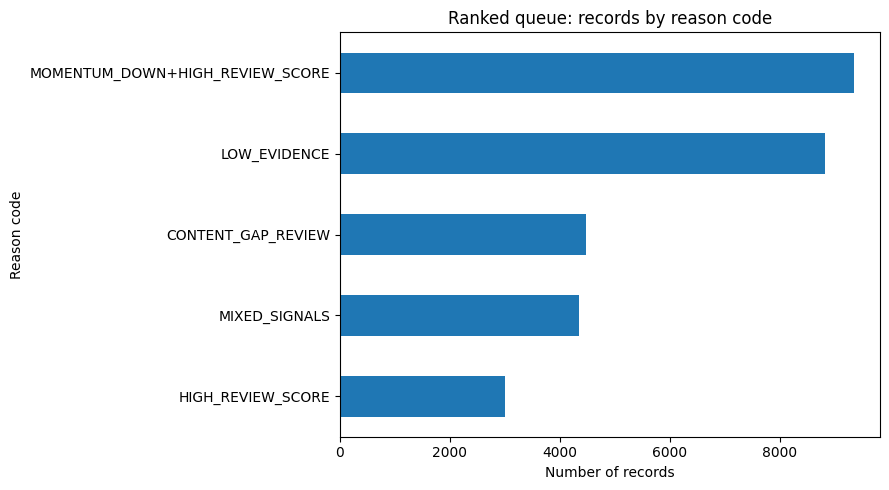

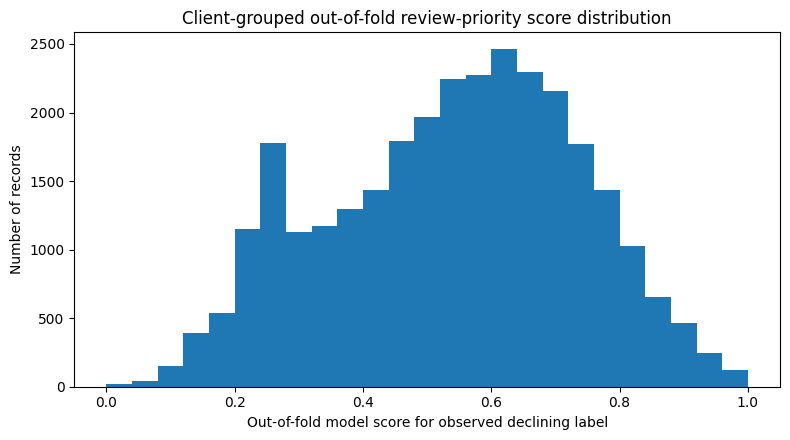

Exports written successfully:
- work/outputs/w07_ranked_content_action_queue.csv (8,090,237 bytes)
- work/outputs/w07_action_playbook_metrics.json (1,604 bytes)
- work/figures/w07_reason_code_counts.png (50,486 bytes)
- work/figures/w07_priority_score_distribution.png (41,241 bytes)

Validation checks passed.
Queue rows: 30000
In-sample scores: 0
Scoring method: 5-fold client-grouped out-of-fold

Reminder: keep the generated queue CSV out of Git if repository policy requires it to remain local.


In [8]:
# Export the ranked action queue, validation metrics, and figures.

# Paths are rooted at the repository when discovered; otherwise use the current working directory.
if repo_root is None:
    repo_root = Path.cwd().resolve()

outputs_dir = repo_root / "work" / "outputs"
figures_dir = repo_root / "work" / "figures"

outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

queue_path = outputs_dir / "w07_ranked_content_action_queue.csv"
metrics_path = outputs_dir / "w07_action_playbook_metrics.json"
reason_fig_path = figures_dir / "w07_reason_code_counts.png"
score_fig_path = figures_dir / "w07_priority_score_distribution.png"

# Keep exports minimal and avoid client/content identifiers or private page-level fields.
export_columns = [
    "rank",
    "queue_row_id",
    "review_priority_score",
    "priority_band",
    "reason_code",
    "content_archetype",
    "suggested_action",
    "human_review_check",
    "prior_momentum_pct",
    "word_count",
    "evidence_impressions_pre",
    "model_score_is_in_sample",
    "score_method",
]

queue[export_columns].to_csv(queue_path, index=False)

# Updated metrics and limitations.
metrics_payload = {
    "assignment": "ML-10 Content Action Playbook",
    "dataset_rows": int(len(model_df)),
    "feature_count": int(len(feature_cols)),
    "target_definition": "trend_direction == 'down' in supplied snapshot",
    "queue_rows": int(len(queue)),
    "reason_code_counts": {
        str(k): int(v)
        for k, v in queue["reason_code"].value_counts().items()
    },
    "grouped_holdout_metrics": holdout_metrics,
    "queue_score_method": "5-fold client-grouped out-of-fold scoring",
    "queue_score_note": "Queue scores use 5-fold client-grouped out-of-fold scoring for relative review prioritization; they are not guaranteed future predictions or calibrated refresh-benefit probabilities.",
    "validation_note": "Client-grouped holdout is not time-forward validation; queue scores use 5-fold client-grouped out-of-fold scoring and are not guaranteed future predictions.",
    "limits": [
        "feature timestamps not independently verified",
        "grouped split is not time-forward",
        "observational proxy label does not establish causality",
        "out-of-fold ranking scores do not guarantee future performance",
        "scores should not be interpreted as calibrated refresh-benefit probabilities",
        "human review is required before taking editorial or technical action",
    ],
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

# Figure 1: Records by reason code.
reason_counts = queue["reason_code"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
reason_counts.plot(kind="barh", ax=ax)
ax.set_title("Ranked queue: records by reason code")
ax.set_xlabel("Number of records")
ax.set_ylabel("Reason code")
fig.tight_layout()
fig.savefig(reason_fig_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figure 2: Correctly label the out-of-fold score distribution.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(queue["review_priority_score"], bins=25)
ax.set_title(
    "Client-grouped out-of-fold review-priority score distribution"
)
ax.set_xlabel("Out-of-fold model score for observed declining label")
ax.set_ylabel("Number of records")
fig.tight_layout()
fig.savefig(score_fig_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Verify that the queue contains out-of-fold scores before reporting exports.
assert len(queue) == len(model_df)
assert queue["queue_row_id"].is_unique
assert queue["model_score_is_in_sample"].eq(False).all()
assert queue["score_method"].eq(
    "5-fold client-grouped out-of-fold"
).all()

# Verify that the JSON contains the corrected scoring description.
with open(metrics_path, "r", encoding="utf-8") as f:
    saved_metrics = json.load(f)

assert saved_metrics["queue_score_method"] == (
    "5-fold client-grouped out-of-fold scoring"
)
assert "not time-forward validation" in saved_metrics["validation_note"]

print("Exports written successfully:")
for path in [
    queue_path,
    metrics_path,
    reason_fig_path,
    score_fig_path,
]:
    print(
        f"- {path.relative_to(repo_root)} "
        f"({path.stat().st_size:,} bytes)"
    )

print("\nValidation checks passed.")
print("Queue rows:", len(queue))
print("In-sample scores:", int(queue["model_score_is_in_sample"].sum()))
print("Scoring method:", queue["score_method"].iloc[0])
print(
    "\nReminder: keep the generated queue CSV out of Git "
    "if repository policy requires it to remain local."
)

## Self-check

Before submission, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere in the outputs or exports
- [ ] Claims use careful words: observed, measured, directional, decision-support
- [ ] Queue CSV is regenerated under `work/outputs/` and remains uncommitted if excluded by repository policy
- [ ] Reusable figures are saved under `work/figures/`
- [ ] Metrics JSON is reviewed against repository policy and committed if allowed
- [ ] Feature timing and future-prediction limitations remain explicit
- [ ] Notebook is saved/committed as `work/notebooks/w07_action_playbook.ipynb`

**Do not check execution or commit items until you have run the notebook from a clean kernel and verified the resulting files.**